In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the selected dataset
df = pd.read_csv(
    "../dataset/StudentPerformanceFactors.csv"
)

# Separate features and target
X = df.drop("Exam_Score", axis=1)
y = df["Exam_Score"]

# Recreate the original train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Dataset loaded successfully!")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Dataset loaded successfully!
Training samples: 5285
Testing samples: 1322


In [3]:
# Load the saved Ridge Regression model
best_model = joblib.load("../models/best_model.pkl")

print("Model loaded successfully!")
print("Selected model: Ridge Regression")
print("Alpha: 10")

Model loaded successfully!
Selected model: Ridge Regression
Alpha: 10


In [4]:
# Generate predictions using the saved model
y_pred = best_model.predict(X_test)

print("Predictions generated successfully!")
print("Total predictions:", len(y_pred))

# Display first 10 actual and predicted values
comparison = pd.DataFrame({
    "Actual Score": y_test.values,
    "Predicted Score": y_pred
})

comparison["Error"] = (
    comparison["Actual Score"] - comparison["Predicted Score"]
)

comparison["Absolute Error"] = comparison["Error"].abs()

display(comparison.head(10))

Predictions generated successfully!
Total predictions: 1322


,Actual Score,Predicted Score,Error,Absolute Error
0,65,64.537410,0.462590,0.462590
1,65,65.277734,-0.277734,0.277734
2,71,71.505762,-0.505762,0.505762
3,64,64.301678,-0.301678,0.301678
4,66,66.517445,-0.517445,0.517445
5,66,66.622290,-0.622290,0.622290
6,72,72.445767,-0.445767,0.445767
7,66,66.504327,-0.504327,0.504327
8,70,69.977034,0.022966,0.022966
9,70,70.114682,-0.114682,0.114682


In [5]:
# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

# Display results
print("FINAL MODEL EVALUATION")
print("----------------------")
print("Model: Ridge Regression")
print("Alpha: 10")
print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")

FINAL MODEL EVALUATION
----------------------
Model: Ridge Regression
Alpha: 10
MAE:  0.4524
MSE:  3.2549
RMSE: 1.8041
R2 Score: 0.7697


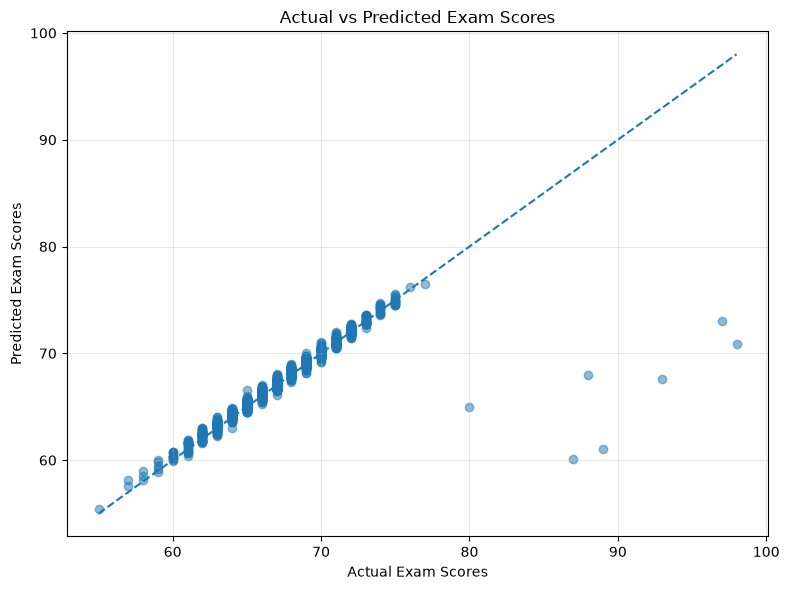

In [6]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

# Perfect prediction reference line
min_score = min(y_test.min(), y_pred.min())
max_score = max(y_test.max(), y_pred.max())

plt.plot(
    [min_score, max_score],
    [min_score, max_score],
    linestyle="--"
)

plt.xlabel("Actual Exam Scores")
plt.ylabel("Predicted Exam Scores")
plt.title("Actual vs Predicted Exam Scores")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

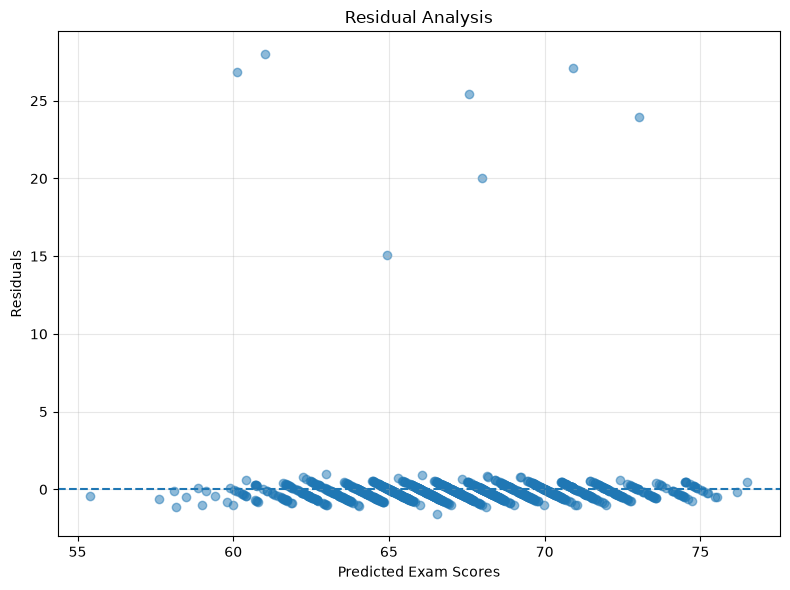

In [7]:
# Calculate residuals
residuals = y_test.values - y_pred

plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Exam Scores")
plt.ylabel("Residuals")
plt.title("Residual Analysis")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# Create detailed prediction error analysis
error_analysis = X_test.copy()

error_analysis["Actual_Score"] = y_test
error_analysis["Predicted_Score"] = y_pred

error_analysis["Residual"] = (
    error_analysis["Actual_Score"] -
    error_analysis["Predicted_Score"]
)

error_analysis["Absolute_Error"] = (
    error_analysis["Residual"].abs()
)

# Sort by largest prediction error
error_analysis = error_analysis.sort_values(
    by="Absolute_Error",
    ascending=False
)

# Display the 10 largest prediction errors
display(error_analysis.head(10))

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,...,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Actual_Score,Predicted_Score,Residual,Absolute_Error
217,19,70,Medium,Low,No,7,54,High,Yes,0,...,Positive,2,Yes,High School,Moderate,Male,89,61.011635,27.988365,27.988365
4192,28,90,Low,Medium,Yes,9,91,Medium,Yes,0,...,Positive,2,No,College,Moderate,Female,98,70.899650,27.100350,27.100350
2687,11,71,Low,Medium,Yes,8,55,Medium,Yes,1,...,Negative,3,No,College,Near,Female,87,60.128594,26.871406,26.871406
4531,26,69,High,High,No,7,95,Low,No,0,...,Negative,3,No,Postgraduate,Near,Female,93,67.555060,25.444940,25.444940
5966,25,99,Medium,Medium,Yes,7,77,Medium,Yes,0,...,Neutral,3,No,High School,Near,Male,97,73.019368,23.980632,23.980632
2513,18,86,High,Medium,No,8,60,Medium,Yes,2,...,Neutral,1,No,College,Near,Male,88,67.998720,20.001280,20.001280
5989,18,61,Medium,Low,Yes,6,91,High,Yes,3,...,Positive,3,No,College,Moderate,Female,80,64.932408,15.067592,15.067592
5725,13,73,Medium,High,No,8,93,Medium,Yes,0,...,Neutral,3,No,Postgraduate,NaN,Female,65,66.554274,-1.554274,1.554274
3543,14,67,Low,Low,Yes,7,66,Low,Yes,0,...,Neutral,4,No,High School,Far,Female,57,58.161045,-1.161045,1.161045
3686,35,68,Low,High,Yes,5,64,Medium,Yes,0,...,Positive,4,Yes,High School,Near,Male,67,68.105963,-1.105963,1.105963


In [9]:
# Combine training features and target
train_analysis = X_train.copy()

train_analysis["Exam_Score"] = y_train

# Count high-scoring students in training data
high_score_counts = {
    "Above 75": (train_analysis["Exam_Score"] > 75).sum(),
    "Above 80": (train_analysis["Exam_Score"] > 80).sum(),
    "Above 85": (train_analysis["Exam_Score"] > 85).sum(),
    "Above 90": (train_analysis["Exam_Score"] > 90).sum(),
    "Above 95": (train_analysis["Exam_Score"] > 95).sum()
}

print("HIGH-SCORE DISTRIBUTION IN TRAINING DATA")
print("----------------------------------------")

for category, count in high_score_counts.items():
    print(f"{category}: {count}")

HIGH-SCORE DISTRIBUTION IN TRAINING DATA
----------------------------------------
Above 75: 67
Above 80: 37
Above 85: 28
Above 90: 19
Above 95: 9


In [10]:
# Select students scoring above 80
high_score_students = train_analysis[
    train_analysis["Exam_Score"] > 80
]

# Analyze important numerical features
print("High-scoring student analysis")
print("--------------------------------")

display(
    high_score_students[
        [
            "Hours_Studied",
            "Attendance",
            "Previous_Scores",
            "Tutoring_Sessions",
            "Exam_Score"
        ]
    ].describe()
)

High-scoring student analysis
--------------------------------


,Hours_Studied,Attendance,Previous_Scores,Tutoring_Sessions,Exam_Score
count,37.000000,37.000000,37.000000,37.000000,37.000000
mean,19.405405,79.945946,74.378378,1.648649,90.594595
std,6.877740,11.340551,16.923605,1.159890,5.974294
min,1.000000,61.000000,52.000000,0.000000,82.000000
25%,16.000000,70.000000,56.000000,1.000000,86.000000
50%,21.000000,77.000000,76.000000,1.000000,91.000000
75%,24.000000,90.000000,90.000000,2.000000,95.000000
max,31.000000,98.000000,98.000000,5.000000,101.000000


In [11]:
comparison_stats = pd.DataFrame({
    "Overall Average": train_analysis[
        [
            "Hours_Studied",
            "Attendance",
            "Previous_Scores",
            "Tutoring_Sessions",
            "Exam_Score"
        ]
    ].mean(),

    "High-Score Average": high_score_students[
        [
            "Hours_Studied",
            "Attendance",
            "Previous_Scores",
            "Tutoring_Sessions",
            "Exam_Score"
        ]
    ].mean()
})

display(comparison_stats)

,Overall Average,High-Score Average
Hours_Studied,19.967077,19.405405
Attendance,79.873605,79.945946
Previous_Scores,75.061116,74.378378
Tutoring_Sessions,1.499527,1.648649
Exam_Score,67.215137,90.594595


In [13]:
# Separate high-score and other students
high_students = train_analysis[
    train_analysis["Exam_Score"] > 80
]

other_students = train_analysis[
    train_analysis["Exam_Score"] <= 80
]

# Identify categorical features
# Identify categorical features
categorical_columns = [
    "Parental_Involvement",
    "Access_to_Resources",
    "Extracurricular_Activities",
    "Motivation_Level",
    "Internet_Access",
    "Family_Income",
    "Teacher_Quality",
    "School_Type",
    "Peer_Influence",
    "Learning_Disabilities",
    "Parental_Education_Level",
    "Distance_from_Home",
    "Gender"
]

# Compare category distributions
for column in categorical_columns:

    print("\n" + "=" * 55)
    print("Feature:", column)
    print("=" * 55)

    comparison = pd.DataFrame({
        "High Score (%)": (
            high_students[column]
            .value_counts(normalize=True) * 100
        ),
        "Other Students (%)": (
            other_students[column]
            .value_counts(normalize=True) * 100
        )
    }).fillna(0)

    display(comparison.round(2))


Feature: Parental_Involvement


,High Score (%),Other Students (%)
Parental_Involvement,,
Medium,37.84,50.99
High,35.14,28.79
Low,27.03,20.22



Feature: Access_to_Resources


,High Score (%),Other Students (%)
Access_to_Resources,,
Medium,48.65,50.40
High,40.54,29.63
Low,10.81,19.97



Feature: Extracurricular_Activities


,High Score (%),Other Students (%)
Extracurricular_Activities,,
Yes,70.27,59.78
No,29.73,40.22


... (16 outputs left out)


Feature: Distance_from_Home


,High Score (%),Other Students (%)
Distance_from_Home,,
Near,59.46,59.03
Moderate,27.03,30.77
Far,13.51,10.20



Feature: Gender


,High Score (%),Other Students (%)
Gender,,
Male,54.05,57.81
Female,45.95,42.19


In [14]:
from scipy.stats import chi2_contingency

chi_square_results = []

for column in categorical_columns:

    contingency_table = pd.crosstab(
        train_analysis[column].fillna("Missing"),
        train_analysis["Exam_Score"] > 80
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    chi_square_results.append({
        "Feature": column,
        "Chi_Square": chi2,
        "P_Value": p_value,
        "Degrees_of_Freedom": dof
    })

chi_square_df = pd.DataFrame(chi_square_results)

chi_square_df = chi_square_df.sort_values(
    by="P_Value"
)

display(chi_square_df.round(4))

,Feature,Chi_Square,P_Value,Degrees_of_Freedom
5,Family_Income,3.2157,0.2003,2
1,Access_to_Resources,3.0428,0.2184,2
2,Extracurricular_Activities,1.2757,0.2587,1
0,Parental_Involvement,2.6022,0.2722,2
9,Learning_Disabilities,0.5708,0.4500,1
3,Motivation_Level,1.2818,0.5268,2
8,Peer_Influence,1.2751,0.5286,2
4,Internet_Access,0.1435,0.7048,1
12,Gender,0.0866,0.7686,1
6,Teacher_Quality,1.0228,0.7957,3


In [15]:
from scipy.stats import chi2_contingency
import pandas as pd

expected_results = []

for column in categorical_columns:

    contingency_table = pd.crosstab(
        train_analysis[column].fillna("Missing"),
        train_analysis["Exam_Score"] > 80
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    expected_results.append({
        "Feature": column,
        "Minimum_Expected_Count": expected.min(),
        "Cells_Below_5": (expected < 5).sum(),
        "Total_Cells": expected.size
    })

expected_df = pd.DataFrame(expected_results)

display(expected_df.round(2))

,Feature,Minimum_Expected_Count,Cells_Below_5,Total_Cells
0,Parental_Involvement,7.50,0,6
1,Access_to_Resources,7.36,0,6
2,Extracurricular_Activities,14.86,0,4
3,Motivation_Level,7.27,0,6
4,Internet_Access,2.88,1,4
5,Family_Income,7.08,0,6
6,Teacher_Quality,0.42,2,8
7,School_Type,11.22,0,4
8,Peer_Influence,7.74,0,6
9,Learning_Disabilities,4.07,1,4


### Categorical Feature Statistical Analysis

A Chi-square test of independence was performed to investigate the association between categorical student-related features and high academic performance (Exam_Score > 80).

The analysis included 13 categorical features. None demonstrated statistically significant evidence of association at the 0.05 significance level.

Expected-frequency validation showed that seven features had no expected cell counts below 5. The remaining features contained at least one low expected frequency, indicating that their Chi-square results should be interpreted cautiously.

The findings suggest that the categorical features did not demonstrate strong statistical associations with high-score classification in this training dataset. However, the relatively small high-score group (37 observations) limits the strength of these conclusions.

Further predictive evaluation and validation are required before making decisions about feature removal or model modifications.